# AI-Assisted E-Commerce Data Analytics & Customer Churn Prediction

**Internship:** AICTE | IBM SkillsBuild Data Analytics with AI Internship 2026  
**Participant:** Akshith Reddy Kathulapalli  
**Workflow:** Masterclass 1 → Data Preparation | Masterclass 2 → EDA & Insights | Masterclass 3 → Predictive Analytics

## Objective
Turn raw e-commerce transaction data into a clean analysis-ready dataset, discover business patterns, and build a leakage-safe customer churn prediction workflow.

> **Important implementation note:** The Masterclass 3 workbook contains conflicting classroom churn definitions (90 days in one step and 180 days in later steps). The supplied dataset ends on 8 Dec 2026, so a full 180-day future observation window is not available. This project therefore uses a transparent **90-day forward no-purchase target** from a historical cutoff of **31 Aug 2026**, while keeping the prediction features strictly historical to avoid target leakage.


## 1. Imports and Configuration

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    roc_auc_score, confusion_matrix, classification_report
)

DATA_PATH = Path("data/cleaned_ecommerce.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Place cleaned_ecommerce.csv inside a folder named 'data' next to this notebook."
    )

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")


## 2. Load the Cleaned Dataset

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=["Order_Date"])

print("Rows:", len(df))
print("Columns:", len(df.columns))
display(df.head())
display(df.info())


Rows: 1810
Columns: 9


,Order_ID,Order_Date,Customer_ID,Product,Category,Region,Quantity,Revenue,Profit
0,1804,2026-01-01,C251,Jacket,Apparel,Mumbai,2,"7,988.00","2,455.00"
1,2790,2026-01-01,C315,Cookware Set,Home,Delhi,5,"25,555.00","6,113.00"
2,1692,2026-01-01,C257,Makeup Kit,Beauty,Kolkata,1,"1,061.00",341.00
3,2817,2026-01-01,C113,Desk,Furniture,Pune,1,"7,650.00","1,406.00"
4,1324,2026-01-01,C456,Jacket,Apparel,Delhi,4,"9,576.00","2,495.00"


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1810 entries, 0 to 1809
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Order_ID     1810 non-null   int64         
 1   Order_Date   1810 non-null   datetime64[ns]
 2   Customer_ID  1810 non-null   object        
 3   Product      1810 non-null   object        
 4   Category     1810 non-null   object        
 5   Region       1810 non-null   object        
 6   Quantity     1810 non-null   int64         
 7   Revenue      1810 non-null   float64       
 8   Profit       1810 non-null   float64       
dtypes: datetime64[ns](1), float64(2), int64(2), object(4)
memory usage: 127.4+ KB


None

## 3. Data Quality Validation

Masterclass 1 emphasizes checking missing values, duplicates, inconsistent categories, invalid dates, formatting problems, and suspicious numerical values before analysis.

In [3]:
print("Missing values:")
display(df.isna().sum())

print("Duplicate rows:", df.duplicated().sum())
print("Date range:", df["Order_Date"].min().date(), "to", df["Order_Date"].max().date())
print("Non-positive quantities:", int((df["Quantity"] <= 0).sum()))
print("Category values:")
display(df["Category"].value_counts())


Missing values:


Order_ID       0
Order_Date     0
Customer_ID    0
Product        0
Category       0
Region         0
Quantity       0
Revenue        0
Profit         0
dtype: int64

Duplicate rows: 0
Date range: 2026-01-01 to 2026-12-08
Non-positive quantities: 0
Category values:


Category
Electronics    530
Apparel        390
Furniture      354
Home           295
Beauty         241
Name: count, dtype: int64

## 4. Business Questions

1. Which months generate the highest and lowest revenue?
2. Which product category generates the most revenue?
3. What proportion of customers are repeat customers?
4. Which regions generate the highest revenue?
5. Which products generate the highest profit?
6. Which customers may be at risk of future churn?


## 5. Exploratory Data Analysis — Five Visualizations

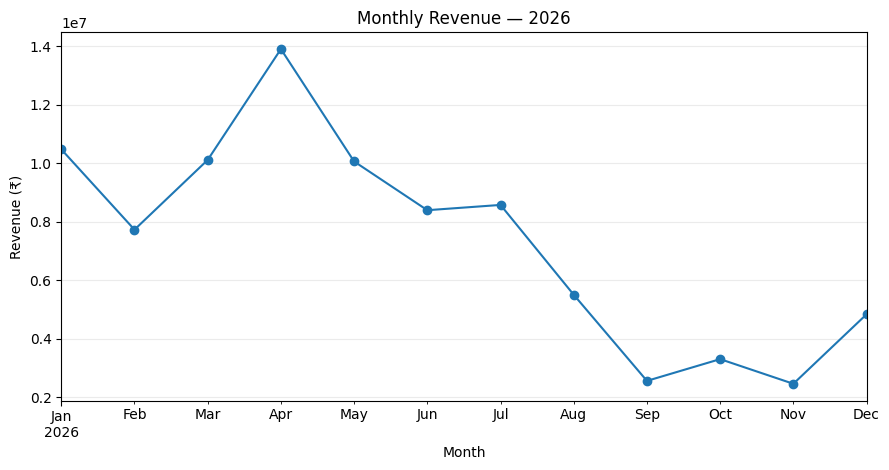

In [4]:
# Visualization 1 — Monthly revenue
monthly_revenue = df.groupby(df["Order_Date"].dt.to_period("M"))["Revenue"].sum()
ax = monthly_revenue.plot(kind="line", marker="o", figsize=(9, 4.8))
ax.set_title("Monthly Revenue — 2026")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (₹)")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


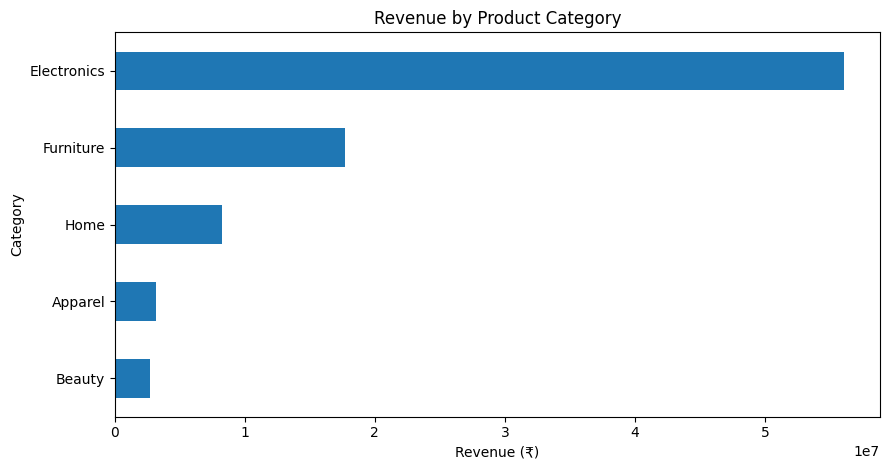

In [5]:
# Visualization 2 — Category revenue
category_revenue = df.groupby("Category")["Revenue"].sum().sort_values(ascending=False)
ax = category_revenue.sort_values().plot(kind="barh", figsize=(9, 4.8))
ax.set_title("Revenue by Product Category")
ax.set_xlabel("Revenue (₹)")
ax.set_ylabel("Category")
plt.tight_layout()
plt.show()


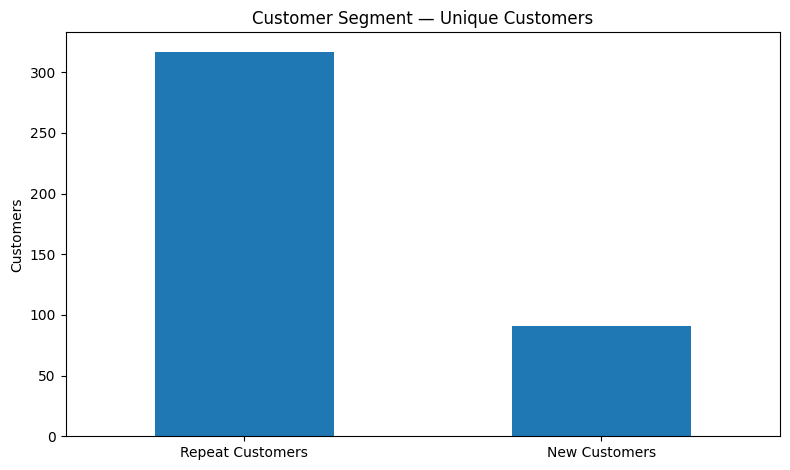

In [6]:
# Visualization 3 — Customer segments
orders_per_customer = df.groupby("Customer_ID")["Order_ID"].nunique()
segments = pd.Series({
    "Repeat Customers": int((orders_per_customer > 1).sum()),
    "New Customers": int((orders_per_customer == 1).sum())
})
ax = segments.plot(kind="bar", figsize=(8, 4.8))
ax.set_title("Customer Segment — Unique Customers")
ax.set_ylabel("Customers")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()


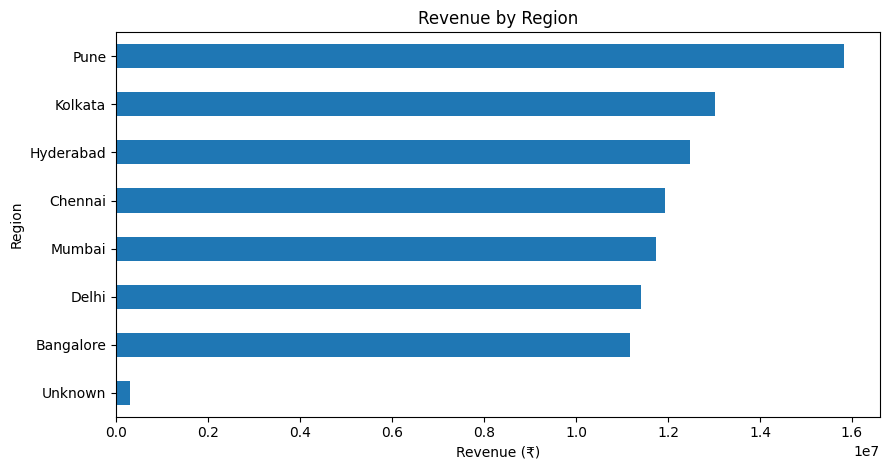

In [7]:
# Visualization 4 — Regional revenue
region_revenue = df.groupby("Region")["Revenue"].sum().sort_values(ascending=False)
ax = region_revenue.sort_values().plot(kind="barh", figsize=(9, 4.8))
ax.set_title("Revenue by Region")
ax.set_xlabel("Revenue (₹)")
ax.set_ylabel("Region")
plt.tight_layout()
plt.show()


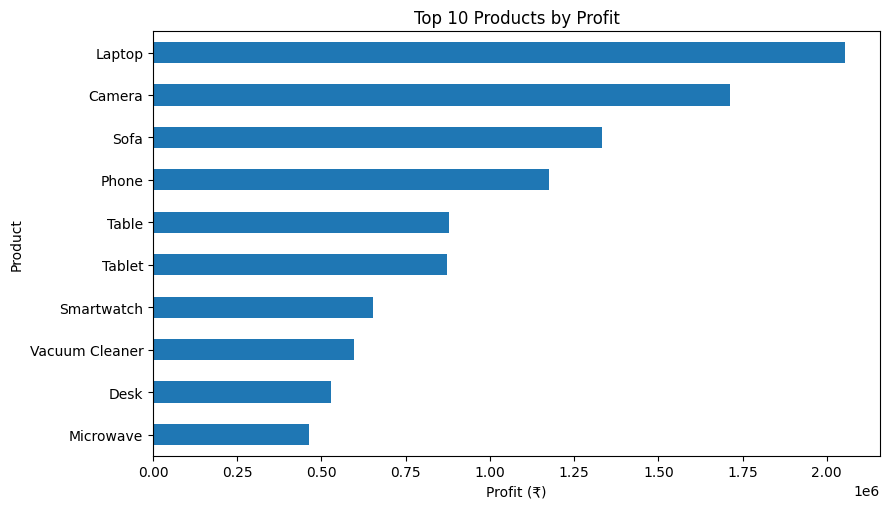

In [8]:
# Visualization 5 — Top product profit
product_profit = df.groupby("Product")["Profit"].sum().sort_values(ascending=False)
ax = product_profit.head(10).sort_values().plot(kind="barh", figsize=(9, 5.2))
ax.set_title("Top 10 Products by Profit")
ax.set_xlabel("Profit (₹)")
ax.set_ylabel("Product")
plt.tight_layout()
plt.show()


## 6. Observations and Business Insights

### Observations
- Revenue peaks in April 2026 and is materially lower in the later months.
- Electronics is the largest revenue category.
- Most unique customers are repeat customers.
- Pune is the highest-revenue region in the cleaned dataset.
- Laptop is the highest-profit named product in the cleaned dataset.

### Insights
- Revenue concentration across months suggests a need for careful off-peak planning.
- Electronics is a major contributor to total revenue, creating category concentration.
- The repeat-customer base is substantial, creating a useful retention audience.
- Regional revenue is distributed across several cities, with Pune leading.
- Product-level profitability can support inventory and merchandising decisions.

### Hypotheses
These are hypotheses, not proven causes:
1. Marketing campaigns or seasonal demand may contribute to monthly revenue variation.
2. Inventory availability may be associated with weaker months.
3. Product launches, pricing, or promotions may contribute to category/product performance.

### Recommendations
1. Plan inventory and operating resources around observed demand variation.
2. Develop retention and repeat-purchase campaigns for the existing customer base.
3. Monitor Electronics inventory and margins because of its large revenue contribution.


## 7. Create Historical Customer-Level Features

In [9]:
# Historical cutoff selected because the supplied data ends on 2026-12-08.
CUTOFF_DATE = pd.Timestamp("2026-08-31")
FUTURE_HORIZON_DAYS = 90
HORIZON_END = CUTOFF_DATE + pd.Timedelta(days=FUTURE_HORIZON_DAYS)

historical = df[df["Order_Date"] <= CUTOFF_DATE].copy()
future_window = df[
    (df["Order_Date"] > CUTOFF_DATE) &
    (df["Order_Date"] <= HORIZON_END)
].copy()

customer_df = (
    historical.groupby("Customer_ID")
    .agg(
        Order_Count=("Order_ID", "nunique"),
        Total_Revenue=("Revenue", "sum"),
        Avg_Order_Value=("Revenue", "mean"),
        First_Purchase=("Order_Date", "min"),
        Last_Purchase=("Order_Date", "max"),
    )
    .reset_index()
)

customer_df["Recency"] = (
    CUTOFF_DATE - customer_df["Last_Purchase"]
).dt.days
customer_df["Frequency"] = customer_df["Order_Count"]
customer_df["Monetary"] = customer_df["Total_Revenue"]

future_customers = set(future_window["Customer_ID"].unique())
customer_df["Churn_Status"] = (
    ~customer_df["Customer_ID"].isin(future_customers)
).astype(int)

display(customer_df.head(10))
print("Eligible customers:", len(customer_df))
print(customer_df["Churn_Status"].value_counts().rename({0: "Not Churned", 1: "Churned"}))


,Customer_ID,Order_Count,Total_Revenue,Avg_Order_Value,First_Purchase,Last_Purchase,Recency,Frequency,Monetary,Churn_Status
0,C001,1,"65,000.00","65,000.00",2026-01-06,2026-01-06,237,1,"65,000.00",1
1,C002,6,"189,275.00","31,545.83",2026-02-17,2026-06-13,79,6,"189,275.00",0
2,C003,2,"77,737.00","38,868.50",2026-02-03,2026-06-06,86,2,"77,737.00",1
3,C004,4,"67,072.00","16,768.00",2026-03-01,2026-06-07,85,4,"67,072.00",1
4,C005,1,"13,363.00","13,363.00",2026-04-07,2026-04-07,146,1,"13,363.00",1
5,C006,1,"2,590.00","2,590.00",2026-08-19,2026-08-19,12,1,"2,590.00",0
6,C007,3,"99,452.00","33,150.67",2026-04-19,2026-07-29,33,3,"99,452.00",1
7,C008,1,"76,659.00","76,659.00",2026-01-04,2026-01-04,239,1,"76,659.00",1
8,C009,1,"19,312.00","19,312.00",2026-07-06,2026-07-06,56,1,"19,312.00",0
9,C010,2,"28,857.00","14,428.50",2026-01-03,2026-08-08,23,2,"28,857.00",1


Eligible customers: 394
Churn_Status
Churned        273
Not Churned    121
Name: count, dtype: int64


## 8. Leakage Check

The model predicts **future** churn from historical behavior. Recency is calculated only from transactions available on the historical cutoff date; the future window is used only to create the target. Therefore, future transactions are not used as prediction features.

## 9. Logistic Regression Churn Model

In [10]:
FEATURES = ["Recency", "Frequency", "Monetary", "Avg_Order_Value"]
X = customer_df[FEATURES]
y = customer_df["Churn_Status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic_regression", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)

pred = model.predict(X_test)
prob = model.predict_proba(X_test)[:, 1]

print(f"Accuracy : {accuracy_score(y_test, pred):.2%}")
print(f"Precision: {precision_score(y_test, pred, zero_division=0):.2%}")
print(f"Recall   : {recall_score(y_test, pred, zero_division=0):.2%}")
print(f"ROC-AUC  : {roc_auc_score(y_test, prob):.2%}")

cm = confusion_matrix(y_test, pred)
print("\nConfusion matrix:")
print(cm)


Accuracy : 77.78%
Precision: 81.33%
Recall   : 88.41%
ROC-AUC  : 70.24%

Confusion matrix:
[[16 14]
 [ 8 61]]


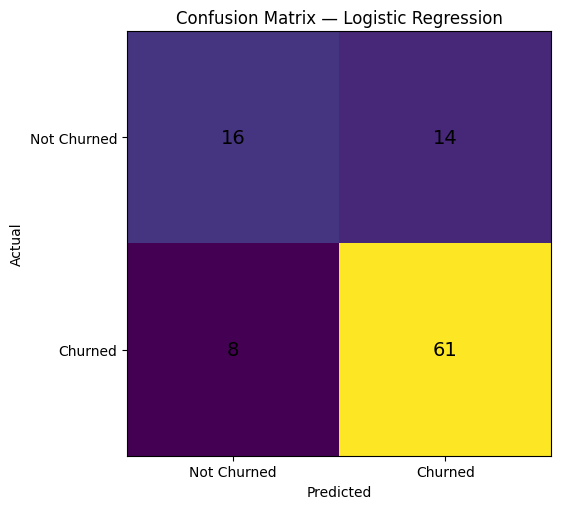

In [11]:
# Confusion matrix visualization
fig, ax = plt.subplots(figsize=(6.5, 5.2))
ax.imshow(cm)
ax.set_title("Confusion Matrix — Logistic Regression")
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_xticks([0, 1], ["Not Churned", "Churned"])
ax.set_yticks([0, 1], ["Not Churned", "Churned"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14)
plt.tight_layout()
plt.show()


## 10. Customer Risk Scoring

Risk levels follow the Masterclass 3 workbook:
- **Below 40%:** Low Risk
- **40% to below 70%:** Medium Risk
- **70% or higher:** High Risk


In [12]:
# Fit on all eligible historical customers to generate the final risk table.
final_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic_regression", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])
final_model.fit(X, y)

customer_df["Churn_Probability"] = final_model.predict_proba(X)[:, 1]

def risk_level(p):
    if p < 0.40:
        return "Low Risk"
    if p < 0.70:
        return "Medium Risk"
    return "High Risk"

customer_df["Risk_Level"] = customer_df["Churn_Probability"].apply(risk_level)

risk_table = customer_df[
    ["Customer_ID", "Recency", "Frequency", "Monetary",
     "Churn_Probability", "Risk_Level"]
].sort_values("Churn_Probability", ascending=False)

risk_table["Churn_Probability"] = risk_table["Churn_Probability"].round(4)

display(risk_table.head(20))


,Customer_ID,Recency,Frequency,Monetary,Churn_Probability,Risk_Level
287,C339,122,1,"373,970.00",0.83,High Risk
16,C019,36,1,"339,312.00",0.81,High Risk
19,C022,150,1,"297,340.00",0.80,High Risk
293,C348,30,1,"283,560.00",0.78,High Risk
198,C240,35,1,"272,964.00",0.78,High Risk
379,C463,137,1,"220,884.00",0.76,High Risk
91,C109,109,1,"211,650.00",0.75,High Risk
263,C311,191,1,"166,170.00",0.74,High Risk
73,C084,134,1,"131,802.00",0.71,High Risk
322,C380,156,1,"127,374.00",0.71,High Risk


## 11. Business Interpretation

The model output is a prioritization signal, not proof of why customers churn. Patterns such as higher recency or lower purchase frequency can be **associated with** higher predicted risk, but the model does not establish causation.

Possible actions include:
- Prioritize high-risk customers for retention outreach.
- Test personalized offers or replenishment reminders.
- Review recent-purchase inactivity alongside product/category history.
- Track campaign response and subsequent purchases.
- Re-train the model when additional future transaction data becomes available.


## 12. Final Project Output

The completed workflow produces:

**Raw data → Cleaned data → EDA → Business insights → Historical customer features → RFM features → Future churn target → Logistic regression → Churn probability → Risk level → Business actions**

### Limitations
- The supplied workbook contains conflicting 90-day and 180-day classroom churn definitions.
- The supplied transaction data ends on 8 Dec 2026, so this implementation uses a 90-day future observation window.
- The model is a baseline logistic-regression model and should be validated on additional future data before production use.
- Predictions indicate risk; they do not establish causal reasons for customer behavior.
